<a href="https://colab.research.google.com/github/AntonioAldamaG/MachineLearning/blob/main/Unidad2/Proyecto_Unidad_2_An%C3%A1lisis_Predictivo_de_la_Tasa_de_Asesinatos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine y Deep Learning
##Unidad 2

##**Proyecto Final Unidad 2 Random Forest**

Docente: Jose Gabriel Rodriguez Rivas

Alumnos:

Antonio Manuel Aldama Gandara

Alejandro Herrera Gracia

Jesús Aarón Retana Suárez

Juan David Zuñiga Herrera

In [247]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
df = pd.read_csv("DATASET_Asesinatos.csv", encoding="latin1")

In [248]:
df.head()

,Estado,id_area,habitantes,area_km2,ingresos_medios,edad_media_poblacion,densidad_poblacional,indice_gini,tasa_desempleo_juvenil,porcentaje_sin_diploma_secundaria,porcentaje_hogares_monoparentales,gasto_policial_per_capita,inversion_programas_sociales_per_capita,tiempo_respuesta_emergencias_min,porcentaje_zonas_verdes,tasa_asesinatos_por_100mil
0,Puebla,1,207953,26.70,48018,40.8,7787.47,0.522,21.8,30.3,40.0,867,240,3.0,5.0,27.1
1,Durango,2,80226,17.39,50295,42.4,4612.66,0.346,19.2,18.9,23.5,706,458,3.0,11.1,13.6
2,Tabasco,3,260806,70.69,50795,39.5,3689.22,0.417,23.0,33.5,23.8,981,403,4.3,8.1,20.6
3,Baja California Sur,4,969508,830.49,68910,27.3,1167.39,0.399,28.8,17.7,23.5,951,326,7.5,16.1,18.5
4,Aguascalientes,5,69478,30.59,54248,36.2,2271.26,0.422,16.4,33.6,27.6,563,353,7.2,10.6,16.8


## Ejecución 1 con parametros por defecto

In [249]:
# Variables predictoras
X = df[['indice_gini', 'tasa_desempleo_juvenil', 'porcentaje_sin_diploma_secundaria', 'ingresos_medios',
        'densidad_poblacional', 'gasto_policial_per_capita','inversion_programas_sociales_per_capita']]

# Variable objetivo
y = df['tasa_asesinatos_por_100mil']

# Dividir los datos en entrenamiento y prueba
X_train_1, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Parámetros del modelo
rf_model_1 = RandomForestRegressor(random_state=42)

# Entrenar el modelo
rf_model_1.fit(X_train_1, y_train)

# Predicciones con los datos de entrenamiento
y_pred_train_rf = rf_model_1.predict(X_train_1)
r2_train_rf = r2_score(y_train, y_pred_train_rf)

# Predicciones con los datos de prueba
y_pred_rf1 = rf_model_1.predict(X_test)
mse_rf = mean_squared_error(y_test, y_pred_rf1)
r2_rf = r2_score(y_test, y_pred_rf1)

# Calcular RMSE
import numpy as np
rmse = np.sqrt(mse_rf)

# Mostrar resultados
print("EVALUACIÓN DEL MODELO RANDOM FOREST 1")
print(f"Coeficiente de determinación entrenamiento (R² train): {r2_train_rf:.4f}")
print(f"Coeficiente de determinación prueba (R² test): {r2_rf:.4f}")
print(f"Error cuadrático medio (MSE): {mse_rf:.2f}")
print(f"Raíz del error cuadrático medio (RMSE): {rmse:.2f}")

EVALUACIÓN DEL MODELO RANDOM FOREST 1
Coeficiente de determinación entrenamiento (R² train): 0.9263
Coeficiente de determinación prueba (R² test): 0.5054
Error cuadrático medio (MSE): 9.97
Raíz del error cuadrático medio (RMSE): 3.16


Ejecucion 2 con n_estimators de 200

In [250]:
# Variables predictorias
X = df[['indice_gini', 'tasa_desempleo_juvenil', 'porcentaje_sin_diploma_secundaria','ingresos_medios']]
## Para este modelo se seleccionaron una menor cantidad de variables y estas en especifico
## ya que son las que obtubieron una mayor importancia, lo que quiere decir que contribuyen más al algoritmo.
y = df['tasa_asesinatos_por_100mil']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Parametros del modelo
rf_model_2 = RandomForestRegressor(random_state=42, n_estimators=200)

rf_model_2.fit(X_train, y_train)

y_pred_train_rf = rf_model_2.predict(X_train)
r2_train_rf = r2_score(y_train, y_pred_train_rf)


y_pred_rf = rf_model_2.predict(X_test)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

import numpy as np
rmse = np.sqrt(mse_rf)
print(f"Coeficiente de determinación entrenamiento (R² train): {r2_train_rf:.4f}")
print(f"Coeficiente de determinación prueba (R² test): {r2_rf:.4f}")
print(f"Error cuadrático medio (MSE): {mse_rf:.2f}")
print(f"Raíz del Error cuadrático medio (RMSE): {rmse:.2f}")

Coeficiente de determinación entrenamiento (R² train): 0.9259
Coeficiente de determinación prueba (R² test): 0.4950
Error cuadrático medio (MSE): 10.18
Raíz del Error cuadrático medio (RMSE): 3.19


Text(0.5, 1.0, 'Predicciones vs Valores reales - Modelo')

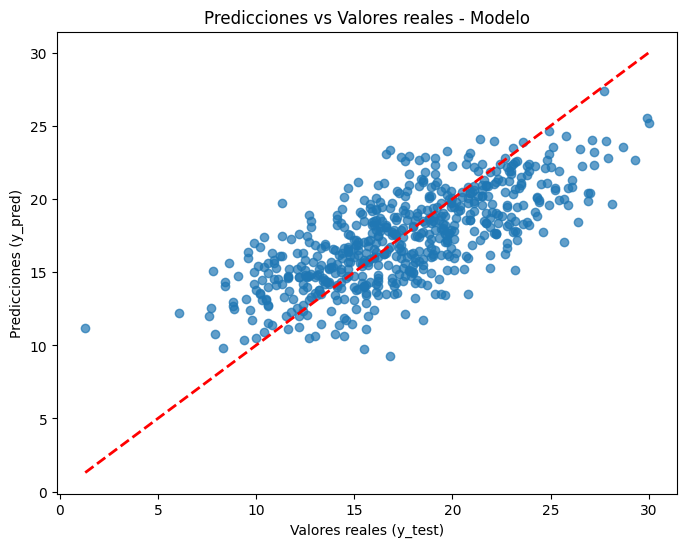

In [251]:
plt.figure(figsize=(8, 6))

# Puntos: X = valores reales, Y = predicciones
plt.scatter(y_test, y_pred_rf1, alpha=0.7)

# Línea de referencia: y = x
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Valores reales (y_test)")
plt.ylabel("Predicciones (y_pred)")
plt.title("Predicciones vs Valores reales - Modelo")

IMPORTANCIA DE LAS CARACTERÍSTICAS - RANDOM FOREST 1
                         Característica  Importancia
                            indice_gini     0.357128
      porcentaje_sin_diploma_secundaria     0.175428
                 tasa_desempleo_juvenil     0.153034
                        ingresos_medios     0.118712
              gasto_policial_per_capita     0.067573
inversion_programas_sociales_per_capita     0.066171
                   densidad_poblacional     0.061955


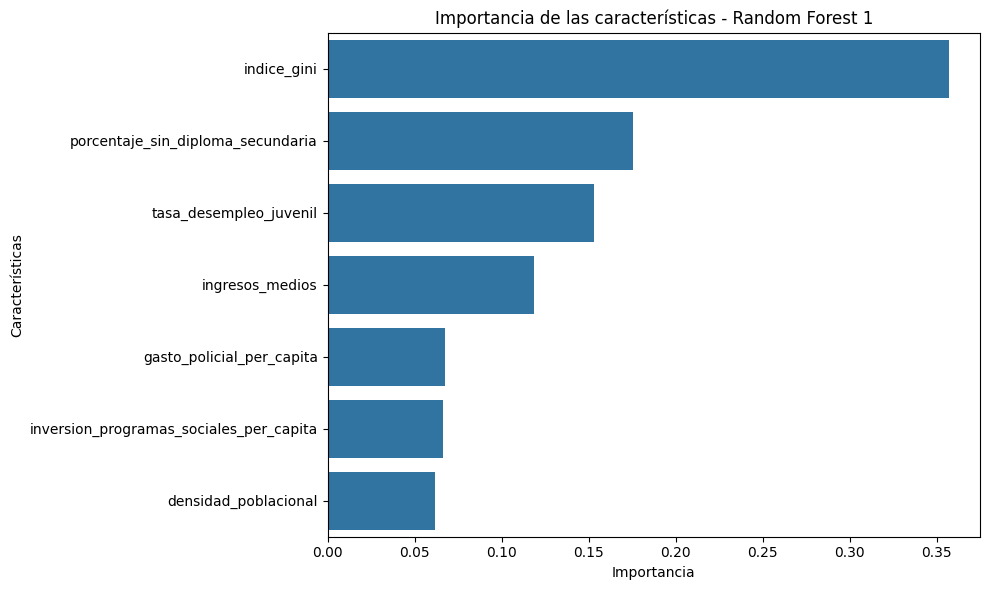

In [252]:
# Obtener la importancia de las características
importancias = rf_model_1.feature_importances_

# Crear el DataFrame con los nombres de las variables
importancia = pd.DataFrame({
    'Característica': X_train_1.columns,
    'Importancia': importancias
})

# Ordenar de mayor a menor
importancia = importancia.sort_values(
    by='Importancia',
    ascending=False
)

# Mostrar resultados
print("IMPORTANCIA DE LAS CARACTERÍSTICAS - RANDOM FOREST 1")
print(importancia.to_string(index=False))

# Graficar resultados
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancia,
    x='Importancia',
    y='Característica'
)

plt.title('Importancia de las características - Random Forest 1')
plt.xlabel('Importancia')
plt.ylabel('Características')
plt.tight_layout()
plt.show()


# **Conclusiones Requeridas**

1. **Interpretación vs. Predicción ¿cuáles son los
3 factores con la mayor influencia (positiva o negativa) sobre la tasa de asesinatos?** De acuerdo con el modelo Random Forest de 200 árboles, los tres factores que tuvieron mayor influencia en la predicción de la tasa de asesinatos fueron el índice de Gini, el porcentaje de personas sin diploma de secundaria y la tasa de desempleo juvenil, con niveles de importancia de 357128, 0.175428 y 0 0.153034, respectivamente.
El índice de Gini resultó ser el factor más importante, lo que sugiere que la desigualdad económica tiene una fuerte relación con la variación de la tasa de asesinatos. En segundo lugar aparece el porcentaje de población sin diploma de secundaria, indicando que los niveles educativos también son relevantes para explicar el fenómeno. Finalmente, la tasa de desempleo juvenil se encuentra entre los factores con mayor impacto, lo que muestra la importancia de las oportunidades laborales para los jóvenes.

2. **Mejor Rendimiento: ¿Qué algoritmo arrojó el valor de (R2) más alto en el conjunto de
prueba? ¿A qué cree que se debe su superioridad?** El modelo Random Forest con parametros default obtuvo un R² de prueba de 0.5054, lo que significa que explica aproximadamente el 50.54% de la variabilidad de la tasa de asesinatos en los datos de prueba. Además, presentó un RMSE de 3.16, indicando un error de predicción relativamente moderado.

3. **Importancia de Variables: Compare las tres variables más importantes en el modelo
de RLM (los coeficientes más grandes) con las tres variables más importantes
reportadas por Random Forest. ¿Son las mismas? No, ¿por qué cree que
el modelo no lineal se enfoca en variables diferentes?** RLM evalúa relaciones lineales directas entre cada variable y la tasa de asesinatos, mientras que Random Forest puede detectar relaciones no lineales e interacciones complejas entre varias variables al mismo tiempo. Por ello, el modelo no lineal puede identificar variables que no necesariamente tienen los coeficientes más altos en una regresión tradicional, pero que contribuyen significativamente a mejorar las predicciones.

4. **Sobreajuste (Overfitting): ¿Cómo se demostró el sobreajuste en el modelo de Random forest? (Debe explicarse con la diferencia entre el (R2) de entrenamiento y el (R2)
de prueba).** El sobreajuste en Random Forest se evidencia al comparar el coeficiente de determinación (R²) obtenido en entrenamiento con el obtenido en prueba. Si el modelo alcanza un valor muy alto de R² durante el entrenamiento pero un valor considerablemente menor en los datos de prueba, significa que aprendió muy bien los patrones específicos de los datos de entrenamiento, pero pierde capacidad para generalizar a datos nuevos, el objetivo ideal es obtener valores de R² similares en entrenamiento y prueba, ya que esto demuestra una mejor capacidad de generalización del modelo.

5. **Recomendación de Modelo: Si el objetivo del proyecto fuera convencer al gobierno
de invertir en un programa social específico, ¿qué tipo de modelo recomendaría utilizar
para respaldar su argumento y por qué?** Las variables identificadas como más importantes por el modelo podrían servir como guía para priorizar inversiones y diseñar programas sociales enfocados en los factores con mayor impacto potencial. De esta forma, las decisiones gubernamentales estarían respaldadas por evidencia obtenida mediante técnicas avanzadas de aprendizaje automático.